# Hotel Booking Analysis: Reducing Cancellations and Increasing Revenue

**Dataset:** Hotel Booking Demand (City Hotel and Resort Hotel, Portugal, 2015-2017)
**Tools:** Python (pandas, numpy, matplotlib, seaborn)

## 1. Business Problem

Hotels lose revenue when guests cancel. A canceled room-night that cannot be resold is lost income, and overbooking to compensate risks walking guests.

**Questions this analysis answers**
1. How many bookings are canceled, and who cancels?
2. When are demand and prices highest?
3. Which channels and customer types are most valuable?
4. What should the hotel do to reduce cancellations and raise revenue?

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (9, 4.5)
plt.rcParams["axes.titlesize"] = 13

df = pd.read_csv("hotel_bookings_2.csv")
print("Shape:", df.shape)
df.head()

Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,1/7/2015
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,1/7/2015
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2/7/2015
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2/7/2015
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,3/7/2015


## 2. Understanding the Data

Each row is one booking. Column groups:

| Group | Columns |
|---|---|
| Target | `is_canceled` (1 = canceled) |
| Timing | `lead_time`, arrival year/month/week/day, weekend and week nights |
| Guests | `adults`, `children`, `babies`, `country`, `is_repeated_guest` |
| Channel | `market_segment`, `distribution_channel`, `agent`, `company` |
| Booking terms | `deposit_type`, `customer_type`, `meal`, `days_in_waiting_list` |
| Room | `reserved_room_type`, `assigned_room_type`, `booking_changes` |
| Money | `adr` (average daily rate) |
| Extras | `required_car_parking_spaces`, `total_of_special_requests` |
| Outcome | `reservation_status`, `reservation_status_date` |

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [3]:
missing = df.isna().sum()
print(missing[missing > 0])
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().T[["mean", "min", "max"]]

children         4
country        488
agent        16340
company     112593
dtype: int64



Duplicate rows: 31994


,mean,min,max
is_canceled,0.370416,0.00,1.0
lead_time,104.011416,0.00,737.0
arrival_date_year,2016.156554,2015.00,2017.0
arrival_date_week_number,27.165173,1.00,53.0
arrival_date_day_of_month,15.798241,1.00,31.0
stays_in_weekend_nights,0.927599,0.00,19.0
stays_in_week_nights,2.500302,0.00,50.0
adults,1.856403,0.00,55.0
children,0.103890,0.00,10.0
babies,0.007949,0.00,10.0


## 3. Data Cleaning

| Issue | Action |
|---|---|
| Duplicate rows | Drop (some may be genuine identical bookings, but dropping is the standard approach) |
| Missing `children` | Fill with 0 |
| Missing `country` | Fill with "Unknown" |
| Missing `agent` | Fill with 0 (no agent) |
| `company` is about 94% empty | Drop the column |
| Zero guests / zero nights | Remove, as these are invalid bookings |
| Zero or negative `adr` | Exclude (mostly complimentary stays) |
| Extreme `adr` outlier (5,400) | Remove |
| `meal = Undefined` | Treat as `SC` (no meal package) |

In [4]:
raw_rows = len(df)
d = df.drop_duplicates().copy()
print(f"Rows after removing duplicates: {len(d):,} (removed {raw_rows - len(d):,})")

d["children"] = d["children"].fillna(0).astype(int)
d["country"] = d["country"].fillna("Unknown")
d["agent"] = d["agent"].fillna(0).astype(int)
d = d.drop(columns=["company"])
d["meal"] = d["meal"].replace("Undefined", "SC")

d = d[(d.adults + d.children + d.babies) > 0]
d = d[(d.stays_in_weekend_nights + d.stays_in_week_nights) > 0]
d = d[(d.adr >= 0) & (d.adr < 1000)]

# Feature engineering
months = ["January","February","March","April","May","June","July",
          "August","September","October","November","December"]
d["arrival_date_month"] = pd.Categorical(d["arrival_date_month"], categories=months, ordered=True)
d["total_nights"] = d.stays_in_weekend_nights + d.stays_in_week_nights
d["total_guests"] = d.adults + d.children + d.babies
d["revenue"] = d.adr * d.total_nights
d["has_children"] = (d.children + d.babies) > 0
d["lead_time_bucket"] = pd.cut(
    d.lead_time, [-1, 7, 30, 90, 180, 365, 800],
    labels=["0-7 days", "8-30", "31-90", "91-180", "181-365", "365+"]
)

d = d.reset_index(drop=True)
print(f"Clean dataset: {d.shape[0]:,} rows, {d.shape[1]} columns")
print("Missing values left:", int(d.isna().sum().sum()))

Rows after removing duplicates: 87,396 (removed 31,994)
Clean dataset: 86,637 rows, 36 columns
Missing values left: 0


## 4. Analysis and Insights

### 4.1 Overall cancellation rate

Overall cancellation rate: 27.7%
hotel
City Hotel      30.2%
Resort Hotel    23.7%
Name: is_canceled, dtype: str


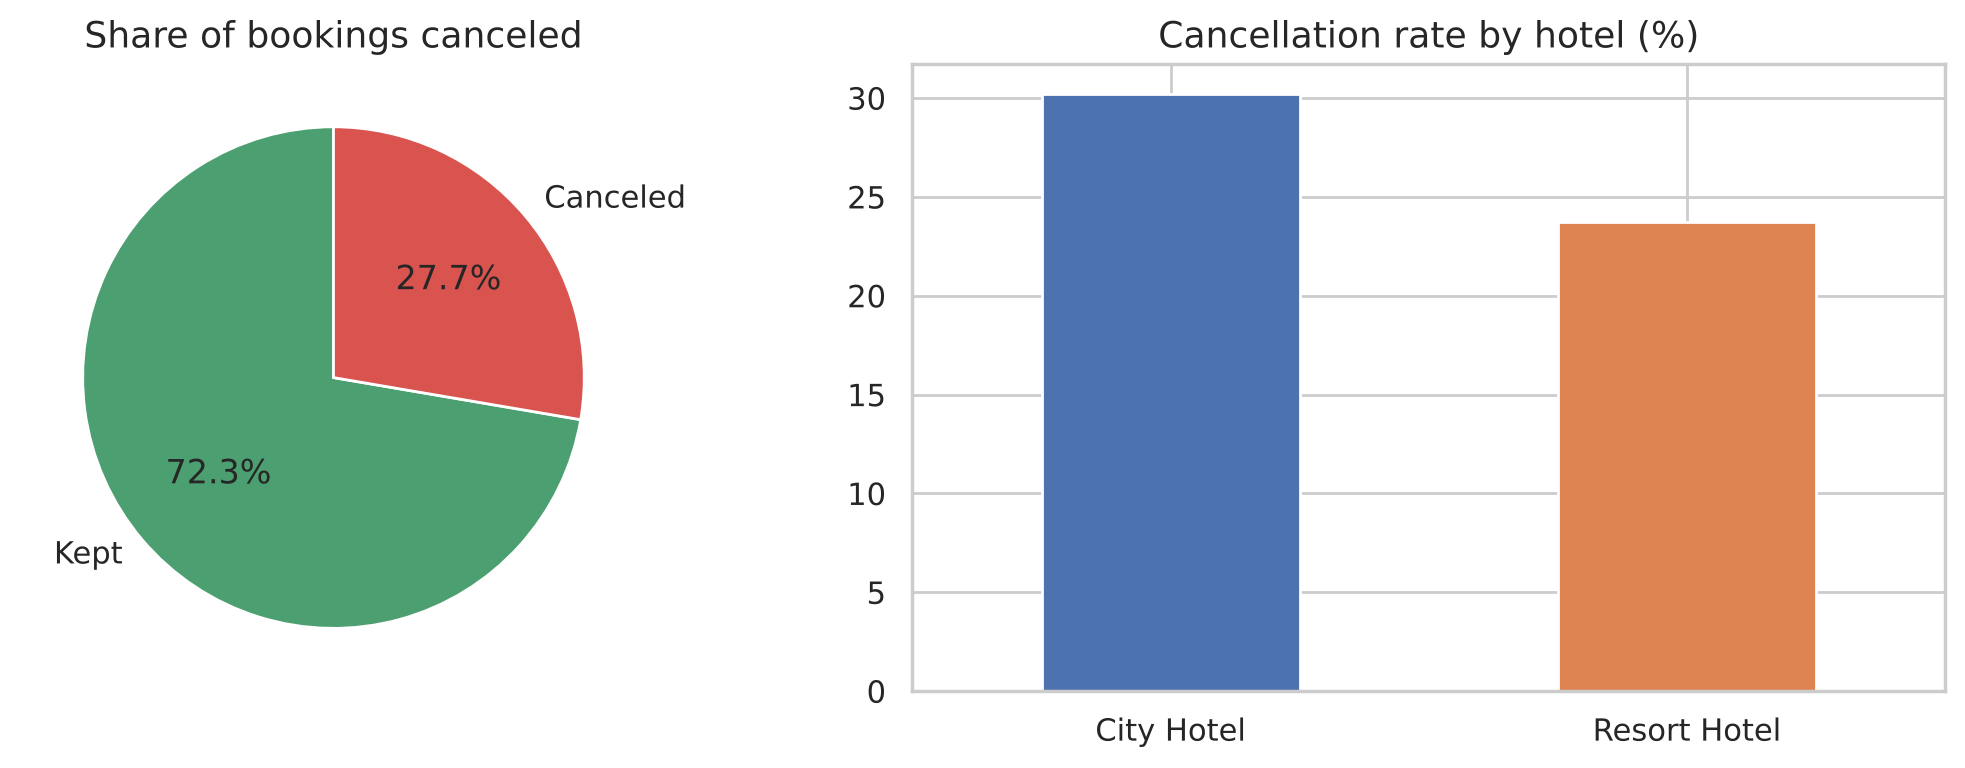

Canceled bookings represent 33.3% of total booked revenue.


In [5]:
overall = d.is_canceled.mean()
by_hotel = d.groupby("hotel").is_canceled.mean()
print(f"Overall cancellation rate: {overall:.1%}")
print(by_hotel.map("{:.1%}".format))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
d.is_canceled.value_counts().rename({0: "Kept", 1: "Canceled"}).plot.pie(
    ax=ax[0], autopct="%1.1f%%", startangle=90, colors=["#4C9F70", "#D9534F"])
ax[0].set_ylabel(""); ax[0].set_title("Share of bookings canceled")
by_hotel.mul(100).plot.bar(ax=ax[1], color=["#4C72B0", "#DD8452"], rot=0)
ax[1].set_title("Cancellation rate by hotel (%)"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

lost = d[d.is_canceled == 1].revenue.sum() / d.revenue.sum()
print(f"Canceled bookings represent {lost:.1%} of total booked revenue.")

**Insight:** Roughly 1 in 4 bookings is canceled, and the City Hotel cancels more than the Resort. Canceled bookings carry about a third of booked revenue.

### 4.2 Lead time vs cancellation

                   mean  count
lead_time_bucket              
0-7 days           8.5%  17855
8-30              25.5%  16234
31-90             32.1%  22633
91-180            35.1%  18190
181-365           39.8%  11164
365+              41.0%    561


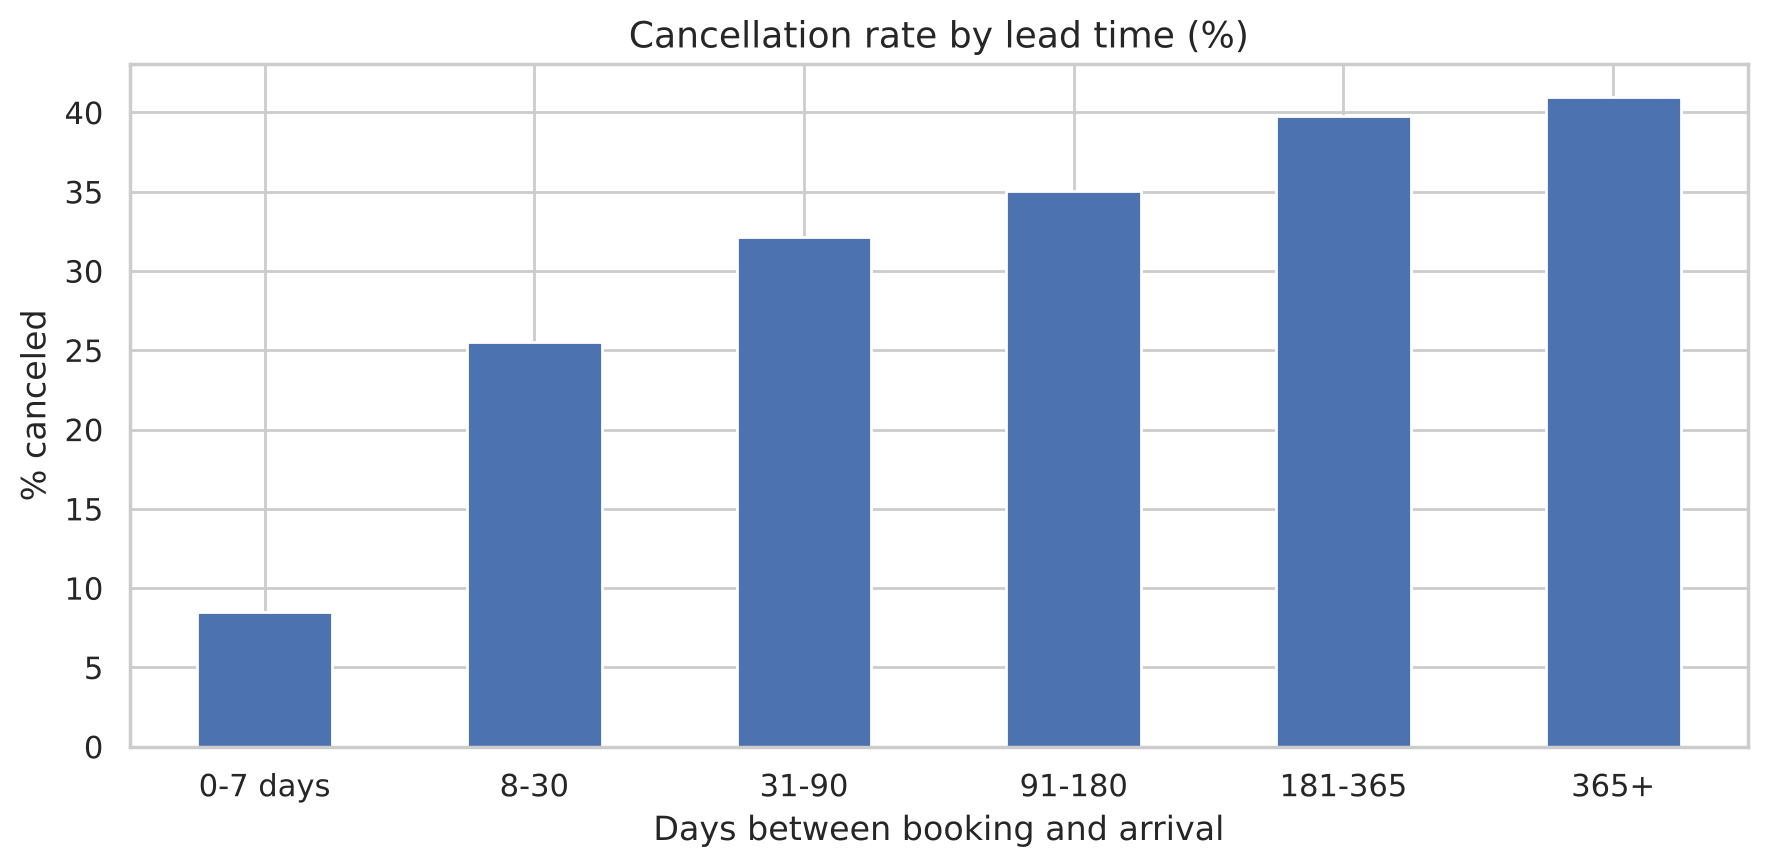

In [6]:
lt = d.groupby("lead_time_bucket", observed=True).is_canceled.agg(["mean", "count"])
print(lt.assign(mean=lt["mean"].map("{:.1%}".format)))

ax = (lt["mean"] * 100).plot.bar(color="#4C72B0", rot=0)
ax.set_title("Cancellation rate by lead time (%)")
ax.set_xlabel("Days between booking and arrival"); ax.set_ylabel("% canceled")
plt.tight_layout(); plt.show()

**Insight:** The longer the gap between booking and arrival, the higher the cancellation rate. Last-minute bookings (within a week) cancel under 10%, while bookings made 6+ months ahead cancel about 40%.

### 4.3 Market segment and customer type

                bookings cancel_rate  avg_adr
market_segment                               
Online TA          51285       35.5%    118.9
Groups              4891       27.2%     75.6
Aviation             222       19.8%    102.4
Offline TA/TO      13748       14.9%     82.2
Direct             11652       14.9%    118.1
Corporate           4155       12.2%     69.1
Complementary        682       12.2%      3.1


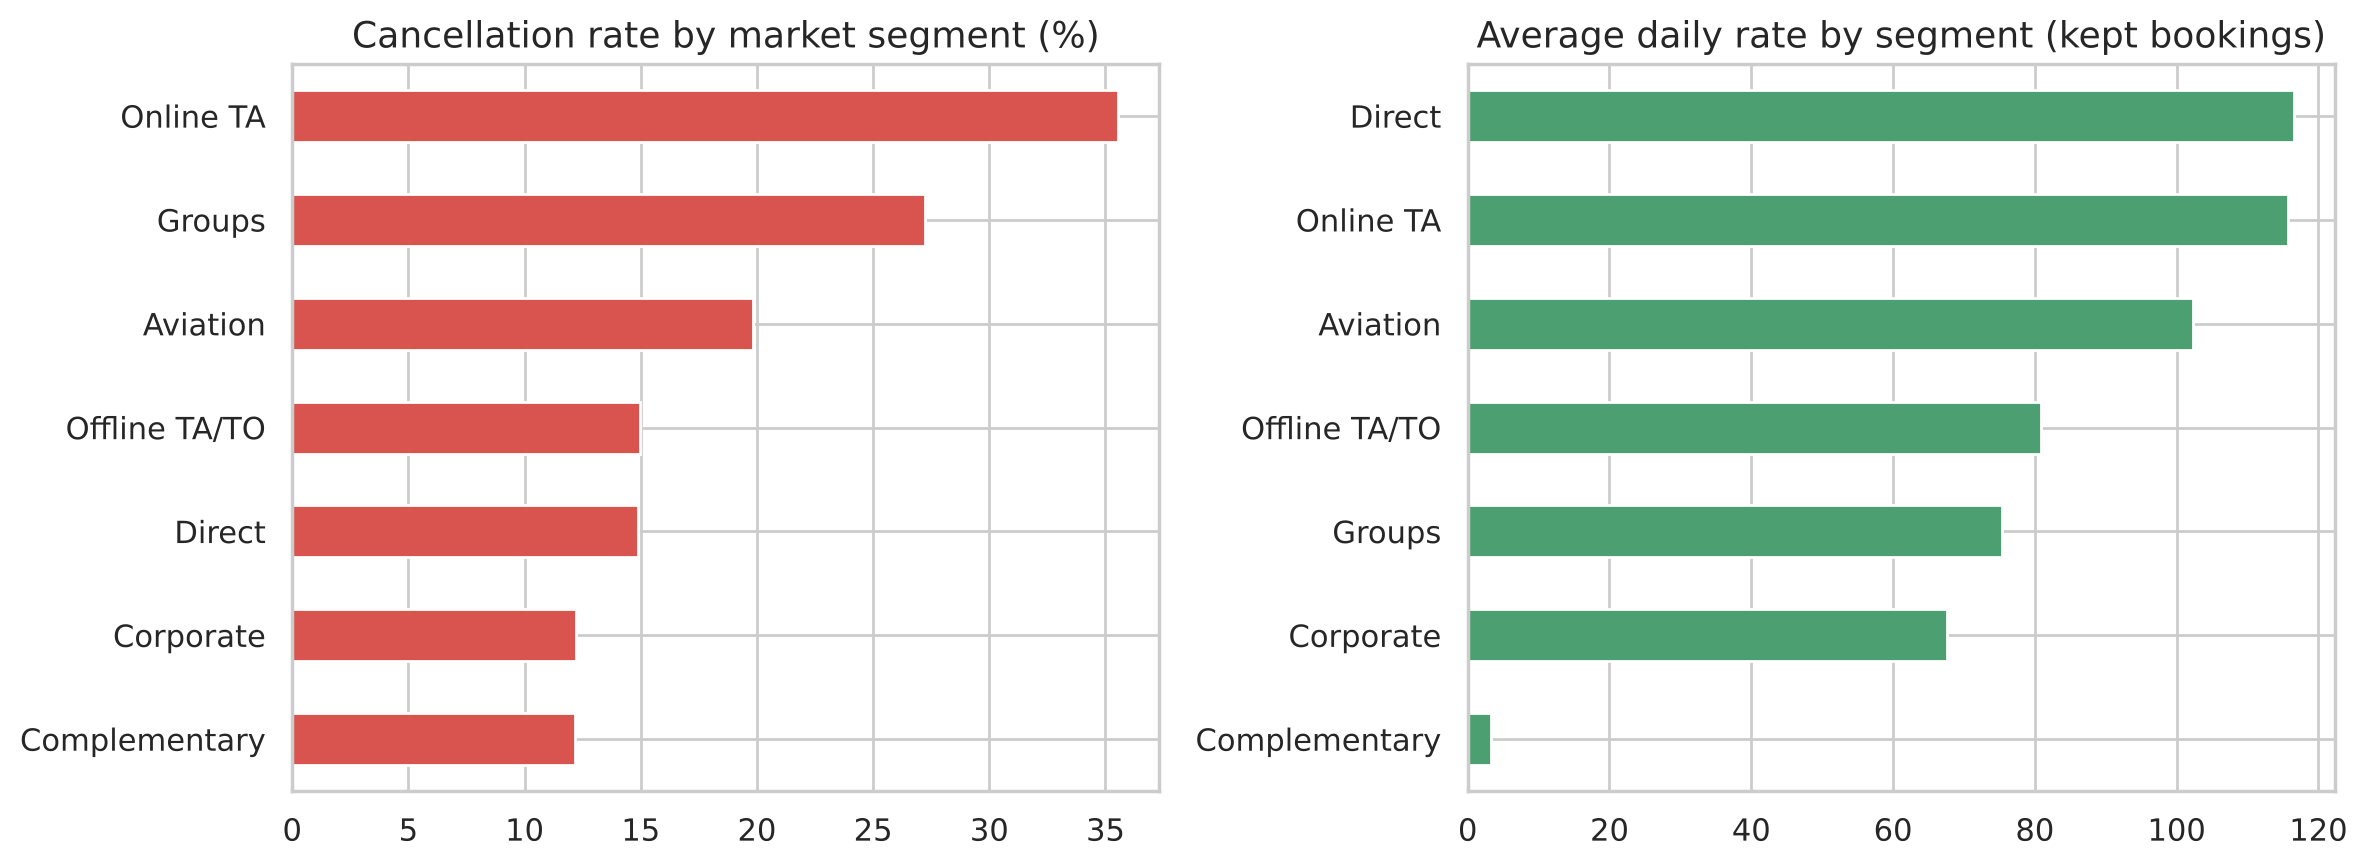

In [7]:
seg = d.groupby("market_segment").agg(
    bookings=("is_canceled", "size"),
    cancel_rate=("is_canceled", "mean"),
    avg_adr=("adr", "mean")
).query("bookings > 100").sort_values("cancel_rate", ascending=False)
print(seg.assign(cancel_rate=seg.cancel_rate.map("{:.1%}".format), avg_adr=seg.avg_adr.round(1)))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
(seg.cancel_rate * 100).sort_values().plot.barh(ax=ax[0], color="#D9534F")
ax[0].set_title("Cancellation rate by market segment (%)"); ax[0].set_ylabel("")
d[d.is_canceled == 0].groupby("market_segment").adr.mean().loc[seg.index].sort_values().plot.barh(ax=ax[1], color="#4C9F70")
ax[1].set_title("Average daily rate by segment (kept bookings)"); ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

**Insight:** Online travel agents bring the most volume but also the highest cancellation rate (about 35%). Direct bookings pay the best rates with a low cancellation rate (about 15%). Corporate bookings are very reliable but lower priced.

### 4.4 Guest behaviour: repeat guests, special requests, country

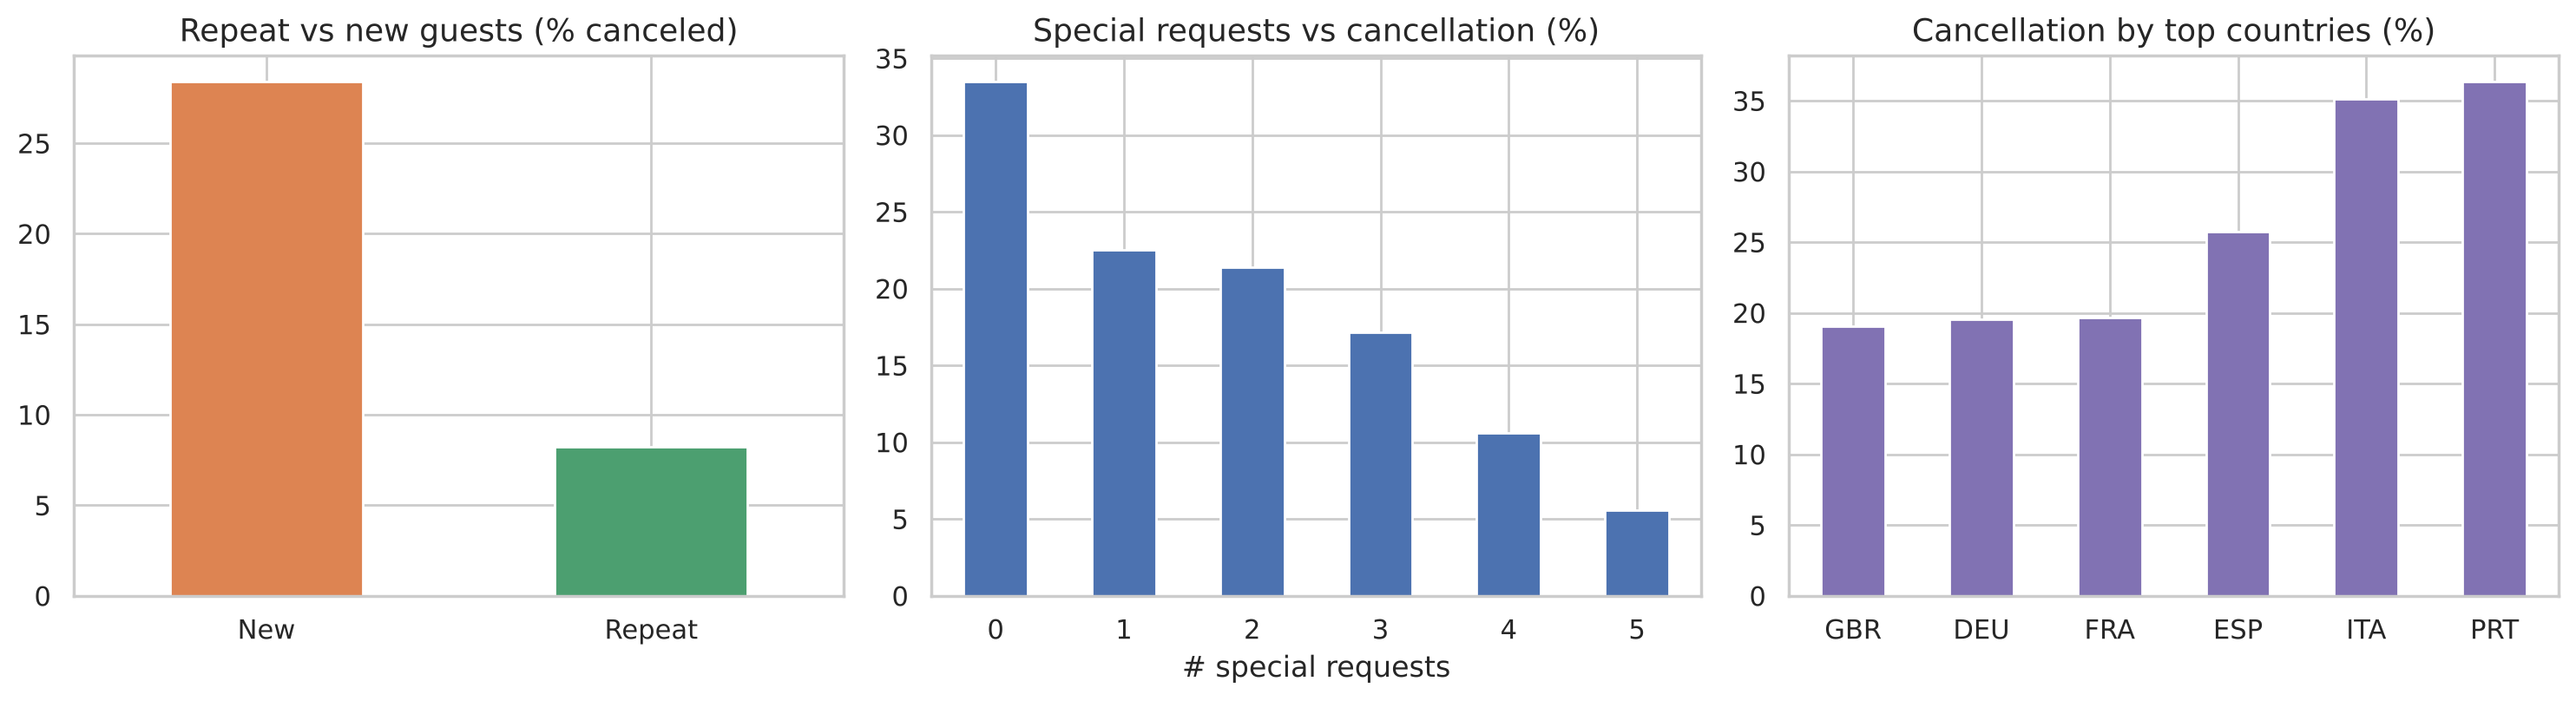

is_repeated_guest
0    0.284
1    0.082
Name: is_canceled, dtype: float64


In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))

(d.groupby("is_repeated_guest").is_canceled.mean() * 100).rename({0: "New", 1: "Repeat"}).plot.bar(ax=ax[0], color=["#DD8452", "#4C9F70"], rot=0)
ax[0].set_title("Repeat vs new guests (% canceled)"); ax[0].set_xlabel("")

(d.groupby("total_of_special_requests").is_canceled.mean() * 100).plot.bar(ax=ax[1], color="#4C72B0", rot=0)
ax[1].set_title("Special requests vs cancellation (%)"); ax[1].set_xlabel("# special requests")

top = d.country.value_counts().head(6).index
(d[d.country.isin(top)].groupby("country").is_canceled.mean() * 100).sort_values().plot.bar(ax=ax[2], color="#8172B3", rot=0)
ax[2].set_title("Cancellation by top countries (%)"); ax[2].set_xlabel("")
plt.tight_layout(); plt.show()

print(d.groupby("is_repeated_guest").is_canceled.mean().round(3))

**Insight:** Repeat guests are far less likely to cancel (about 8% vs 28%). Cancellations fall steadily as a guest makes more special requests. Portuguese guests cancel the most among the top countries (about 36%).

### 4.5 Seasonality and pricing

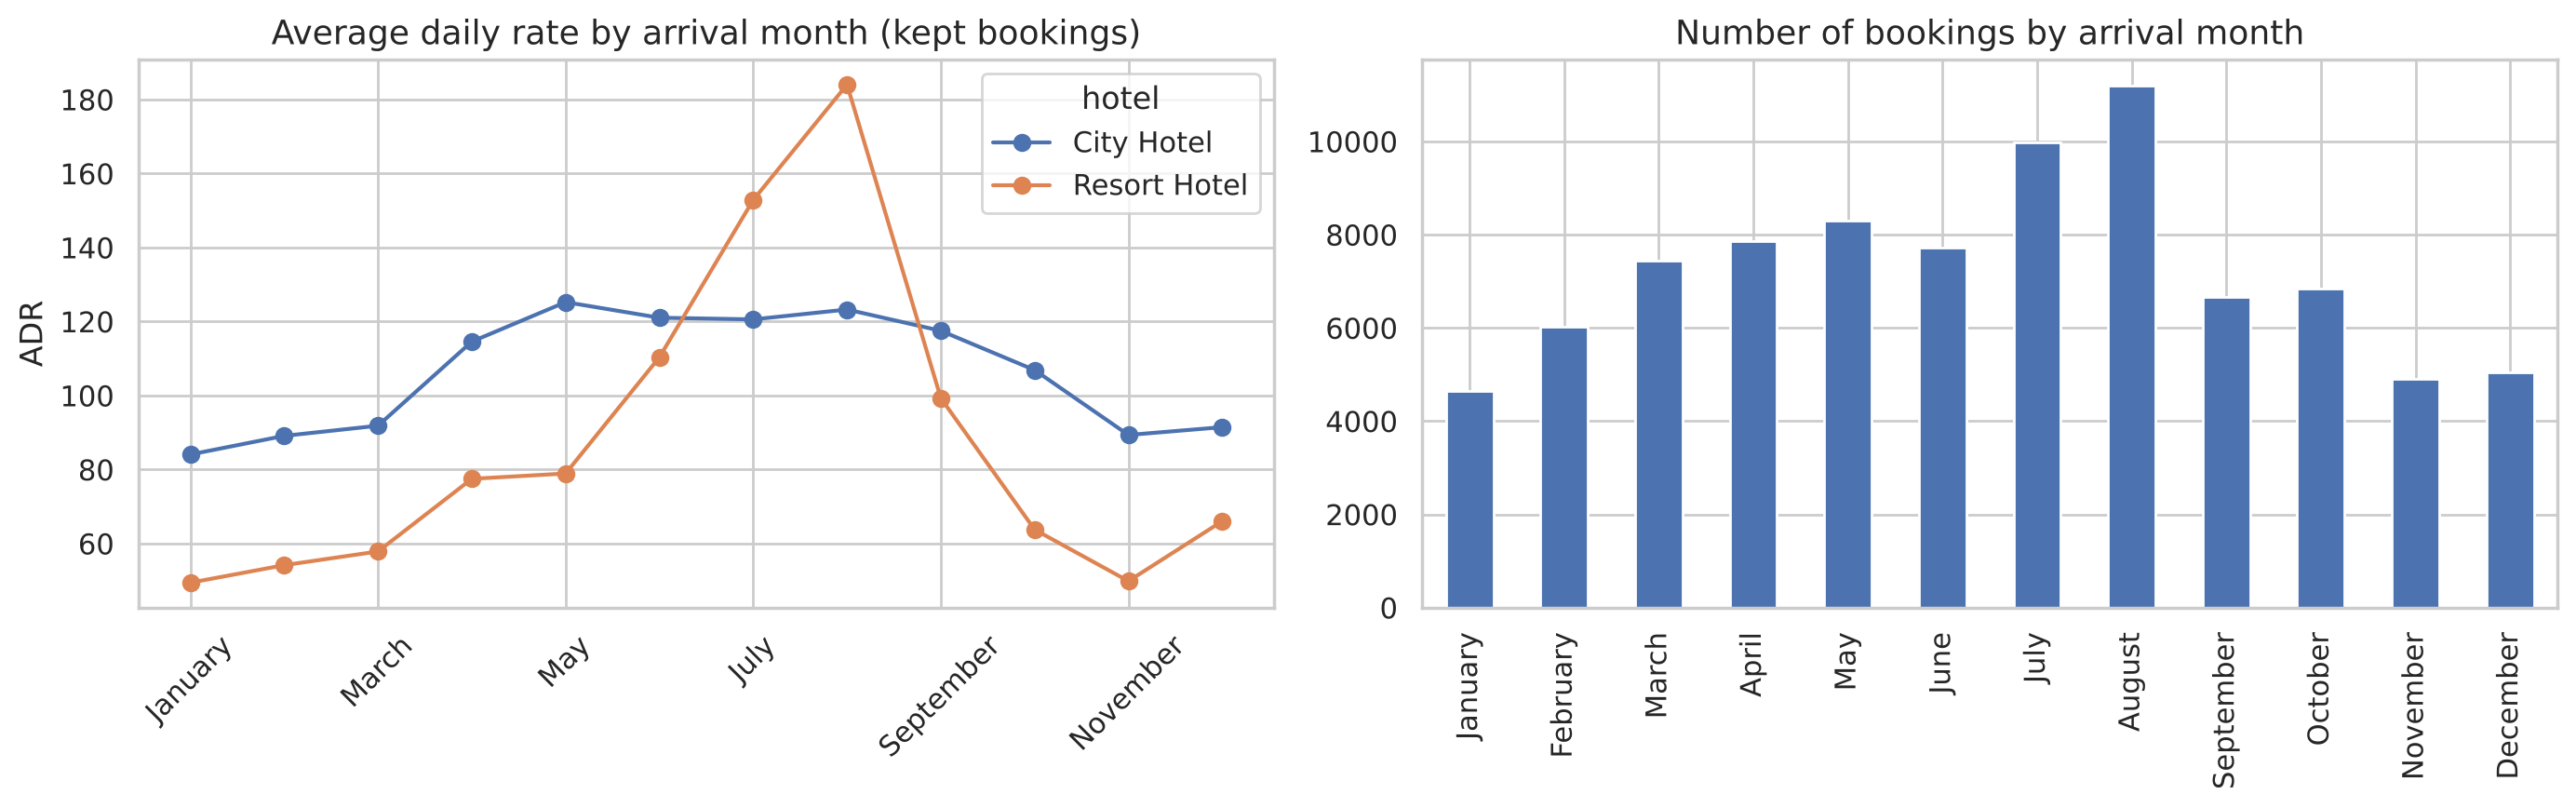

              avg_adr  avg_nights
hotel                            
City Hotel     109.28        3.00
Resort Hotel    94.27        4.26


In [9]:
kept = d[d.is_canceled == 0]
monthly_adr = kept.groupby(["arrival_date_month", "hotel"], observed=True).adr.mean().unstack()
monthly_bk = d.groupby("arrival_date_month", observed=True).size()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
monthly_adr.plot(ax=ax[0], marker="o")
ax[0].set_title("Average daily rate by arrival month (kept bookings)")
ax[0].set_xlabel(""); ax[0].set_ylabel("ADR"); ax[0].tick_params(axis="x", rotation=45)
monthly_bk.plot.bar(ax=ax[1], color="#4C72B0")
ax[1].set_title("Number of bookings by arrival month"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

print(kept.groupby("hotel").agg(avg_adr=("adr", "mean"), avg_nights=("total_nights", "mean")).round(2))

**Insight:** The Resort Hotel is highly seasonal, with rates around 50 in winter and over 180 in August. The City Hotel is much steadier. Bookings peak in July and August and are lowest from November to January.

### 4.6 Cancellation trend over time

arrival_date_year
2015    20.6
2016    26.6
2017    32.0
Name: is_canceled, dtype: float64


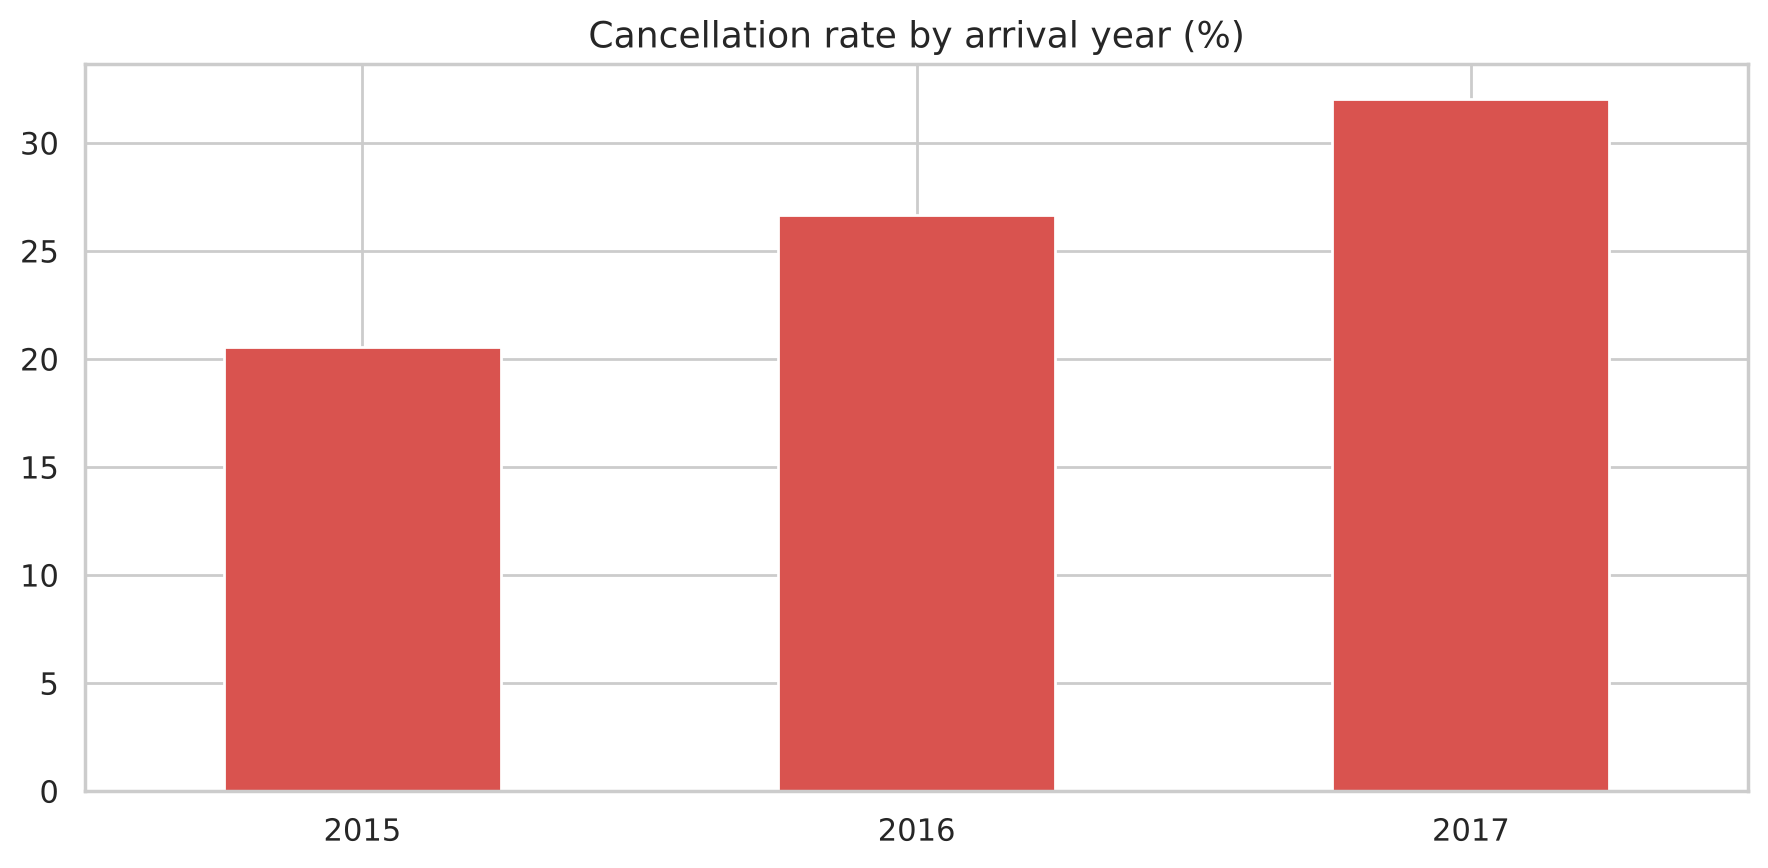

In [10]:
yr = d.groupby("arrival_date_year").is_canceled.mean() * 100
print(yr.round(1))
ax = yr.plot.bar(color="#D9534F", rot=0)
ax.set_title("Cancellation rate by arrival year (%)"); ax.set_xlabel("")
plt.tight_layout(); plt.show()

**Insight:** The cancellation rate rose each year (about 21% in 2015, 27% in 2016, 32% in 2017), so this is a growing problem rather than a stable one. Note that 2015 and 2017 are partial years.

### 4.7 Correlation of numeric features

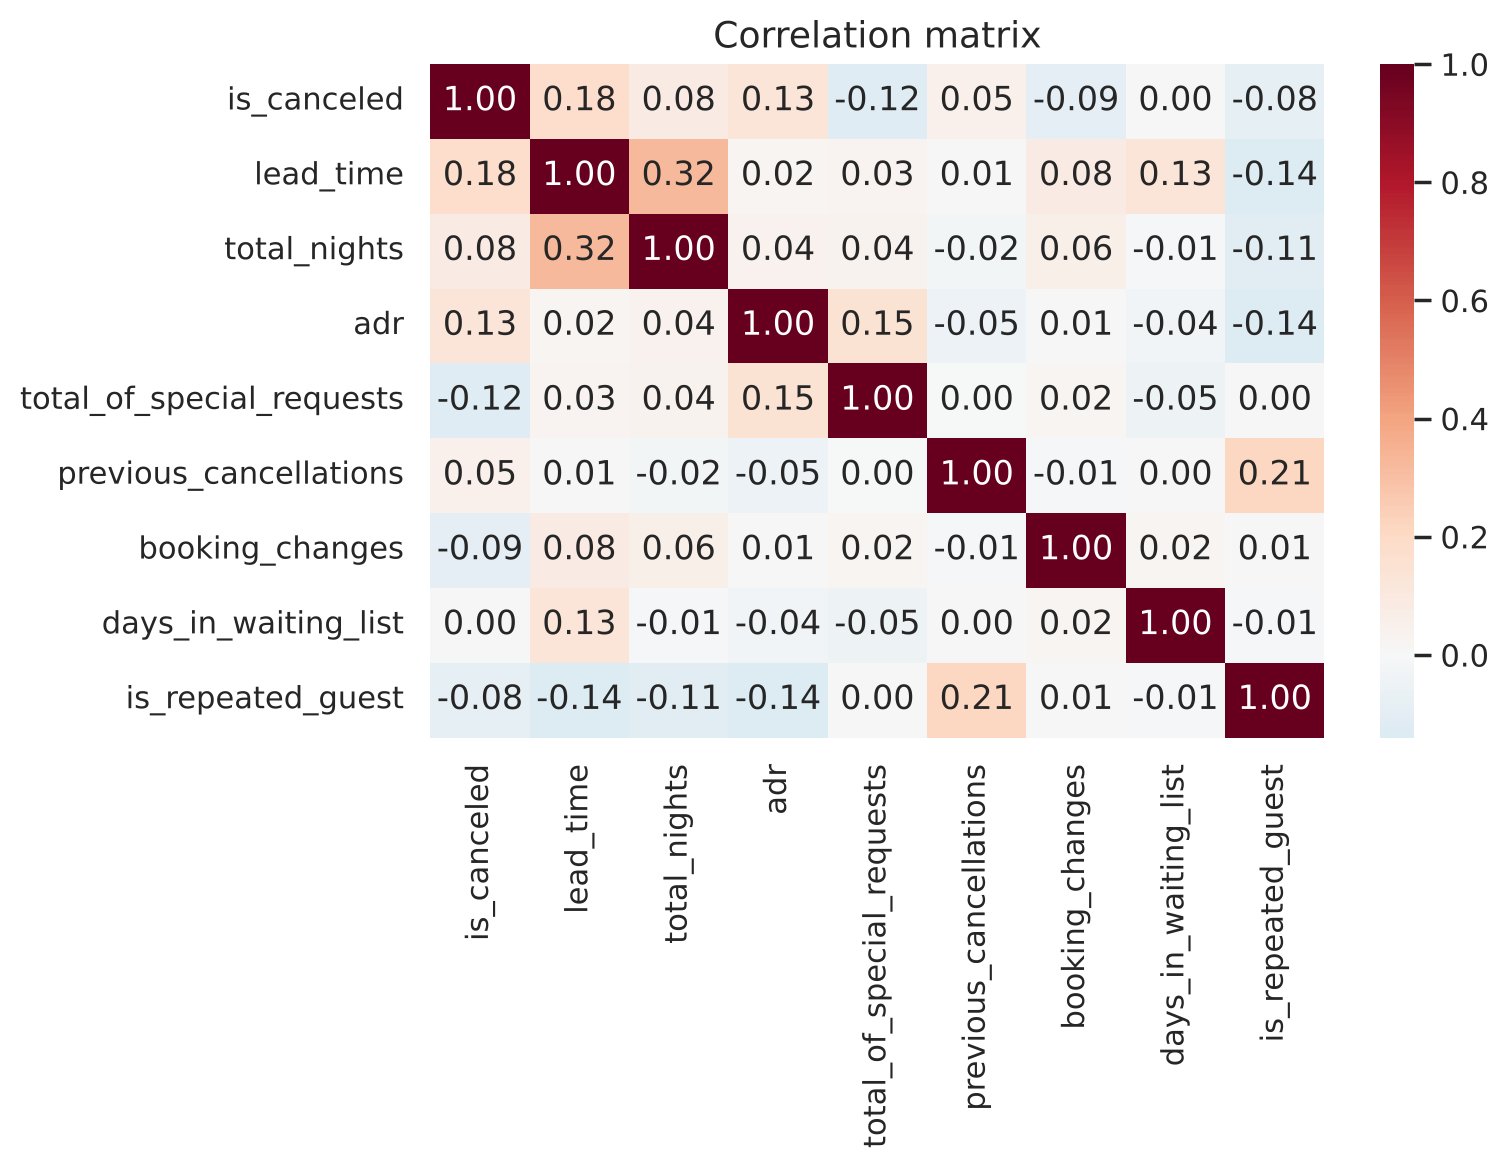

In [11]:
num = d[["is_canceled", "lead_time", "total_nights", "adr", "total_of_special_requests",
         "previous_cancellations", "booking_changes", "days_in_waiting_list", "is_repeated_guest"]]
plt.figure(figsize=(8, 6))
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Correlation matrix"); plt.tight_layout(); plt.show()

### Data quirks to be careful with

- **Parking and room changes:** Guests with a parking space show 0% cancellation, and guests with a room change show about 5%. These are likely recorded at or after check-in, so they reflect the outcome rather than predict it. Do not use them as predictors in a model.
- **Non Refund deposits:** These show a roughly 95% cancellation rate, the opposite of what you would expect. They are mostly group and agent bookings, so this is probably a data-entry artifact.

In [12]:
print("Parking guests cancel rate:", round(d[d.required_car_parking_spaces > 0].is_canceled.mean(), 3))
print("\nDeposit type:")
print(d.groupby("deposit_type").is_canceled.agg(["mean", "count"]).round(3))

Parking guests cancel rate: 0.0

Deposit type:
               mean  count
deposit_type              
No Deposit    0.269  85493
Non Refund    0.947   1037
Refundable    0.243    107


## 5. Business Recommendations

1. **Tier policies by lead time.** Require a deposit or offer a discounted non-refundable rate for bookings made more than 90 days ahead (35-41% cancel).
2. **Manage online travel agent risk.** Use stricter cancellation windows or controlled overbooking on peak dates for the channel with the most volume and the highest cancellations.
3. **Grow direct bookings.** They pay the highest rates with low cancellations. Offer perks such as free breakfast or late checkout for booking direct.
4. **Build loyalty.** Repeat guests are about 3.5 times less likely to cancel.
5. **Capture preferences at booking.** Prompt for special requests, since engaged guests are more committed.
6. **Price dynamically.** Raise Resort rates from June to September and use winter promotions or packages from November to January.
7. **Target the Portuguese market with confirmation reminders**, since it cancels most.
8. **Investigate the rising cancellation trend.** Check whether it is driven by a shift in channel mix.

## 6. Limitations and Next Steps

- The data covers only two hotels in Portugal, so results may not generalise.
- Duplicate removal is a judgment call and slightly changes headline rates (37% before vs about 28% after).
- 2015 and 2017 are partial years, so year-on-year comparisons are approximate.
- **Next step:** build a classification model (logistic regression or random forest) to predict cancellations, excluding the leaky features noted above.